## Load the tokenizer and libraries

This cell imports the libraries and selects the tokenizer encoding for GPT-4.1 mini.


In [1]:
import tiktoken
import pandas as pd
import matplotlib.pyplot as plt

encoding = tiktoken.encoding_for_model("gpt-4.1-mini")

print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


## Create sample prompts

This cell defines short, medium, and long example prompts about RAG.


In [2]:
prompts = {
    "Short": "Explain RAG in simple terms.",

    "Medium": """
    Explain Retrieval-Augmented Generation (RAG).
    Describe how embeddings, vector databases,
    and language models work together.
    """,

    "Long": """
    You are an AI engineering assistant.
    Explain Retrieval-Augmented Generation in detail.
    Cover document loading, chunking, embeddings,
    vector databases, similarity search, retrieval,
    prompt construction, generation, evaluation,
    hallucination reduction, and production deployment.
    Include practical examples and implementation tips.
    """
}

## Count prompt characters, words, and tokens

This cell analyzes each sample prompt and displays the counts in a table.


In [3]:
def analyse_prompt(name, text):
    tokens = encoding.encode(text)

    return {
        "Prompt": name,
        "Characters": len(text),
        "Words": len(text.split()),
        "Tokens": len(tokens)
    }

results = [
    analyse_prompt(name, text)
    for name, text in prompts.items()
]

df = pd.DataFrame(results)
df

,Prompt,Characters,Words,Tokens
0,Short,28,5,7
1,Medium,141,14,27
2,Long,363,36,63


## Estimate prompt input costs

This cell calculates an estimated input cost for each prompt using the configured token price.


In [4]:
INPUT_PRICE_PER_MILLION = 0.40

df["Estimated Input Cost ($)"] = (
    df["Tokens"] / 1_000_000
) * INPUT_PRICE_PER_MILLION

df

,Prompt,Characters,Words,Tokens,Estimated Input Cost ($)
0,Short,28,5,7,0.000003
1,Medium,141,14,27,0.000011
2,Long,363,36,63,0.000025


## Plot prompt token counts

This cell creates a bar chart comparing token counts across the sample prompts.


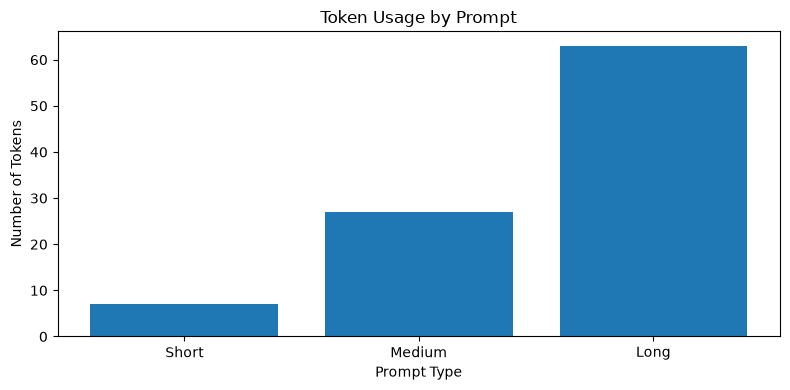

In [5]:
plt.figure(figsize=(8, 4))

plt.bar(df["Prompt"], df["Tokens"])
plt.title("Token Usage by Prompt")
plt.xlabel("Prompt Type")
plt.ylabel("Number of Tokens")
plt.tight_layout()
plt.show()

## Build an interactive token analyzer

Enter a prompt and click Analyze Prompt to view one chart comparing characters, words, and tokens. The chart title also shows the estimated input cost.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import pandas as pd

prompt_input = widgets.Textarea(
    value="Hello, its a great day today. Hope you are doing well",
    placeholder="Enter your prompt here...",
    description="Prompt:",
    layout=widgets.Layout(width="100%", height="120px"),
    style={"description_width": "initial"}
)

analyze_button = widgets.Button(
    description="Analyze Prompt",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="180px")
)

output = widgets.Output()

def analyze_prompt_dashboard(_):
    with output:
        clear_output(wait=True)

        text = prompt_input.value

        if not text.strip():
            display(HTML("<p>Please enter some text to analyze.</p>"))
            return

        tokens = encoding.encode(text)
        token_count = len(tokens)
        word_count = len(text.split())
        cost = (token_count / 1_000_000) * INPUT_PRICE_PER_MILLION

        display(HTML(f"""
        <div style="
            padding: 20px;
            border-radius: 14px;
            background: #111827;
            color: white;
            font-family: sans-serif;
            margin: 12px 0;
        ">
            <h2 style="margin-top:0;">LLM Token Analyzer</h2>
            <p style="color:#9CA3AF;">Prompt analysis overview</p>
            <div style="display:flex; gap:12px; flex-wrap:wrap;">
                <div style="background:#1F2937;padding:16px;border-radius:10px;flex:1;min-width:110px;">
                    <div style="color:#9CA3AF;">Characters</div>
                    <h2>{len(text):,}</h2>
                </div>
                <div style="background:#1F2937;padding:16px;border-radius:10px;flex:1;min-width:110px;">
                    <div style="color:#9CA3AF;">Words</div>
                    <h2>{word_count:,}</h2>
                </div>
                <div style="background:#1F2937;padding:16px;border-radius:10px;flex:1;min-width:110px;">
                    <div style="color:#9CA3AF;">Tokens</div>
                    <h2 style="color:#34D399;">{token_count:,}</h2>
                </div>
                <div style="background:#1F2937;padding:16px;border-radius:10px;flex:1;min-width:150px;">
                    <div style="color:#9CA3AF;">Estimated input cost</div>
                    <h2 style="color:#60A5FA;">${cost:.8f}</h2>
                </div>
            </div>
        </div>
        """))

        # Token ID and text table
        token_data = []

        for position, token_id in enumerate(tokens):
            token_text = encoding.decode([token_id])

            token_data.append({
                "Position": position,
                "Token ID": token_id,
                "Token Text": repr(token_text)
            })

        display(HTML("<h3>🔎 Token Breakdown</h3>"))
        display(pd.DataFrame(token_data))

        # Token count visualization
        display(HTML("<h3>📊 Prompt Composition</h3>"))

        fig, ax = plt.subplots(figsize=(7, 2.5))
        ax.barh(["Characters", "Words", "Tokens"],
                [len(text), word_count, token_count])
        ax.set_title("Text Composition")
        ax.set_xlabel("Count")
        ax.grid(axis="x", alpha=0.2)
        plt.tight_layout()
        plt.show()

analyze_button.on_click(analyze_prompt_dashboard)

display(prompt_input, analyze_button, output)

Textarea(value='Hello, its a great day today. Hope you are doing well', description='Prompt:', layout=Layout(h…

Button(button_style='primary', description='Analyze Prompt', icon='search', layout=Layout(width='180px'), styl…

Output()